In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib import gridspec
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import xarray as xr
import dask
from dask.distributed import Client, LocalCluster
from dask import delayed
import dask.array as da
from dask_jobqueue import PBSCluster
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [5]:
# Setup your PBSCluster
cluster = PBSCluster(
    cores=10,  # Total number of cores across all processes
    memory='300GB',  # Memory per worker
    processes=10,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=10:mem=300GB',  # Resources per worker
    account='UCOR0105',  # Project ID
    walltime='2:00:00',  # Wall time
    #interface='ib0',  # Interface to use (if needed)
)

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

In [6]:
client

<Client: 'tcp://128.117.208.207:33207' processes=10 threads=10, memory=279.40 GiB>

In [7]:
def subset_india(ds):
    if 'lat' in ds.dims:
        ds = ds.rename({'lat':'latitude','lon':'longitude'})
    ds = ds.sel(latitude=slice(40, 0), longitude=slice(50, 100))
    ds = ds.sel(time=~((ds.time.dt.month == 2) & (ds.time.dt.day == 29)))
    return ds

def leap_adjusted_doy(time):
    doy = time.dt.dayofyear
    is_leap = time.dt.is_leap_year
    after_feb = time.dt.month > 2
    return doy - (is_leap & after_feb).astype(int)

ds_t2_anom = xr.open_mfdataset(
    '/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/VAR_2T_ERA5_India_AMJJAS_anom.nc',
    chunks='auto', preprocess=subset_india
)

ds_t2 = ds_t2_anom.sel(longitude=slice(75, 85), latitude=slice(30, 22))
ds_t2 = ds_t2.sel(time=ds_t2.time.dt.month.isin([5, 6, 7, 8])) 
ds_t2 = ds_t2.compute()
ds_t2_ts = ds_t2.mean(dim=['latitude', 'longitude'])
ds_t2_ts = ds_t2_ts.sel(time=ds_t2_ts.time.dt.year < 2024)   # fixed: was ds_t2.time, should be ds_t2_ts.time

ds_t2_ts = ds_t2_ts.assign_coords(doy_adj=leap_adjusted_doy(ds_t2_ts.time))
t2_p90 = ds_t2_ts.groupby('doy_adj').quantile(0.9)

In [8]:
ds_t2 = ds_t2_anom.sel(longitude=slice(75, 85), latitude=slice(30, 22))
ds_t2 = ds_t2.sel(time=ds_t2.time.dt.month.isin([5, 6])) 
ds_t2 = ds_t2.compute()
ds_t2_ts = ds_t2.mean(dim=['latitude', 'longitude'])
ds_t2_ts = ds_t2_ts.sel(time=ds_t2_ts.time.dt.year < 2024)   # fixed: was ds_t2.time, should be ds_t2_ts.time
t2_p90_2024 = ds_t2_ts.quantile(0.9)['anom']
t2_p90_2024

<xarray.DataArray 'anom' ()> Size: 8B
array(3.02426093)
Coordinates:
    quantile  float64 8B 0.9

In [9]:
df2024 = pd.read_csv('./Land-surface-amplification_2024_new.csv')
df90 = pd.read_csv('./Land-surface-amplification_90pct_new.csv')
df10 = pd.read_csv('./Land-surface-amplification_10pct_new.csv')
dates = pd.date_range("2024-05-01", "2024-08-31", freq="D")

In [10]:
def add_event_shading(ax):
    for label, (start, end) in event_windows.items():
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='#fec44f', alpha=0.3, zorder=0)
        #ax.text(pd.Timestamp(start), ax.get_ylim()[1]*0.9, label, fontsize=8, fontweight='bold')

event_windows = {
    'E1': ('2024-05-25', '2024-05-31'),
    'E2': ('2024-06-10', '2024-06-20'),
}


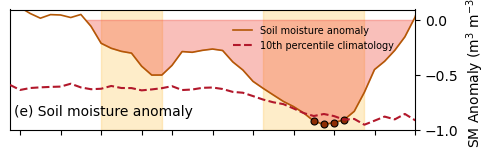

In [44]:
f = plt.figure(figsize=(9, 3))
gs1 = gridspec.GridSpec(1, 1)
gs1.update(left=0.15, right=0.6, bottom=0.2, top=0.6, hspace=0.35)


# ---- Panel (a): SM Dry Anomalies ----
ax1 = f.add_subplot(gs1[0, 0])
sm_anom_nci = df2024['SM_NCI']
sm_threshold = -0.69
data_clr = '#b35806'
data90_clr = '#b2182b'
hline_clr = '#666666'

ax1.plot(dates, df2024['SM_NCI'], color=data_clr, linewidth=1.2, label='Soil moisture anomaly')
ax1.plot(dates, df10['SM_NCI'], color=data90_clr, linewidth=1.5, linestyle='--', label='10th percentile climatology',zorder=100)

sm_mask =  sm_anom_nci <=df10['SM_NCI']
ax1.scatter(dates[sm_mask], sm_anom_nci[sm_mask], facecolor='#8c2d04', edgecolor='k',s=25, linewidth=0.8, zorder=5)
#ax1.axhline(sm_threshold, color=hline_clr, linestyle='-.', linewidth=1.5)#,label=f'S threshold ({sm_threshold:.2f})')
ax1.fill_between(dates, sm_anom_nci, 0, where=(sm_anom_nci <= 0),color='#ef3b2c', alpha=0.325, zorder=1, interpolate=True)
add_event_shading(ax1)
ax1.set_ylabel('SM Anomaly (m$^3$ m$^{-3}$)')
ax1.set_title('(e) Soil moisture anomaly', fontsize=10, x=0.01, y=0.05, ha='left')
ax1.legend(fontsize=7, frameon=False, ncol=1, loc=[0.54,0.63])
ax1.set_xlim([dates[15], dates[55]])
ax1.set_ylim([-1,0.1])
ax1.set_xticklabels([])
ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")
plt.savefig("sm_anomaly.pdf",dpi=300,format='pdf',transparent=True)

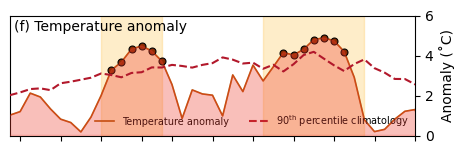

In [45]:
f = plt.figure(figsize=(9, 3))
gs1 = gridspec.GridSpec(1, 1)
gs1.update(left=0.15, right=0.6, bottom=0.2, top=0.6, hspace=0.35)


# ---- Panel (a): SM Dry Anomalies ----
ax1 = f.add_subplot(gs1[0, 0])
data = df2024['T2_anom_NCI']
data90 = t2_p90['anom']
t2_threshold = t2_p90_2024.item()
data_clr = '#b35806'
data90_clr = '#b2182b'
hline_clr = '#666666'

ax1.plot(dates, data, color=data_clr, linewidth=1.2, label='Temperature anomaly')
ax1.plot(dates, data90, color=data90_clr, linewidth=1.5, linestyle='--', label=r'90$^{\mathrm{th}}$ percentile climatology',zorder=100)

sm_mask =  data >=data90
ax1.scatter(dates[sm_mask], data[sm_mask], facecolor='#8c2d04', edgecolor='k',s=25, linewidth=0.8, zorder=5)
ax1.fill_between(dates, data, 0, where=(data >= 0),color='#ef3b2c', alpha=0.325, zorder=10, interpolate=True)
add_event_shading(ax1)
ax1.set_ylabel('Anomaly (˚C)')
ax1.set_title('(f) Temperature anomaly', fontsize=10, x=0.01, y=0.8, ha='left')
ax1.legend(fontsize=7, frameon=False, ncol=2, loc=[0.2,0.025])
ax1.set_xlim([dates[15], dates[55]])
ax1.set_ylim([0,6])
ax1.set_xticklabels([])
ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")
plt.savefig("t2_anomaly.pdf",dpi=300,format='pdf',transparent=True)

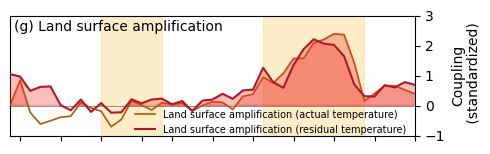

In [46]:
f = plt.figure(figsize=(9, 3))
gs1 = gridspec.GridSpec(1, 1)
gs1.update(left=0.15, right=0.6, bottom=0.2, top=0.6, hspace=0.35)


# ---- Panel (a): SM Dry Anomalies ----
ax1 = f.add_subplot(gs1[0, 0])
data = df2024['P_NCI']#.rolling(window=3).mean()
data_res = df2024['Pres_NCI']
data_clr = '#b35806'
data90_clr = '#b2182b'
hline_clr = '#666666'

ax1.plot(dates, data, color=data_clr, linewidth=1.2, label='Land surface amplification (actual temperature)')
ax1.plot(dates, data_res, color=data90_clr, linewidth=1.5, linestyle='-', label='Land surface amplification (residual temperature)',zorder=100)

sm_mask =  data >=t2_threshold
ax1.axhline(0, color=hline_clr, linestyle='-', linewidth=0.5)
ax1.fill_between(dates, data, 0, where=(data >= 0),color='#ef3b2c', alpha=0.325, zorder=10, interpolate=True)
ax1.fill_between(dates, data_res, 0, where=(data_res >= 0),color='#ef3b2c', alpha=0.325, zorder=10, interpolate=True)

add_event_shading(ax1)
ax1.set_ylabel('Coupling\n (standardized)')
ax1.set_title('(g) Land surface amplification', fontsize=10, x=0.01, y=0.8, ha='left')
ax1.legend(fontsize=7, frameon=False, ncol=1, loc=[0.3,-0.025])
ax1.set_xlim([dates[15], dates[55]])
ax1.set_ylim([-1,3])
ax1.set_xticklabels([])
ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")
plt.savefig("land-coupling_2020.pdf",dpi=300,format='pdf',transparent=True)

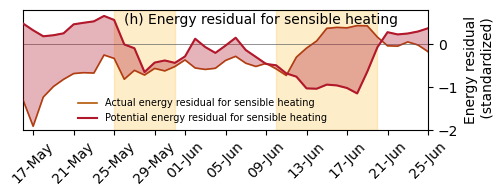

In [47]:
import matplotlib.dates as mdates



f = plt.figure(figsize=(9, 3))
gs1 = gridspec.GridSpec(1, 1)
gs1.update(left=0.15, right=0.6, bottom=0.2, top=0.6, hspace=0.35)


ax1 = f.add_subplot(gs1[0, 0])
h = df2024['H_NCI']
hp = df2024['Hp_NCI']
data_clr = '#b35806'
data90_clr = '#b2182b'
hline_clr = '#666666'

ax1.plot(dates, h, color=data_clr, linewidth=1.2, label="Actual energy residual for sensible heating")
ax1.plot(dates, hp, color=data90_clr, linewidth=1.5, linestyle='-', label="Potential energy residual for sensible heating",zorder=100)


ax1.axhline(0, color=hline_clr, linestyle='-', linewidth=0.5)
ax1.fill_between(dates, h, hp, color=data90_clr, alpha=0.325, zorder=10, interpolate=True)

add_event_shading(ax1)
ax1.set_ylabel('Energy residual\n (standardized)')
ax1.set_title('(h) Energy residual for sensible heating', fontsize=10, x=0.25, y=0.817, ha='left')
ax1.legend(fontsize=7, frameon=False, ncol=1, loc=[0.125,0.025])
ax1.set_xlim([dates[15], dates[55]])
ax1.set_ylim([-2,0.8])
ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
ax1.tick_params(axis='x', rotation=45)
plt.savefig("heat-coupling_2020.pdf",dpi=300,format='pdf',transparent=True)